In [2]:
%pip install requests python-dotenv pandas bibtexparser matplotlib wordcloud nltk

  Using cached matplotlib-3.11.2-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (80 kB)
  Using cached wordcloud-1.9.6-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.manylinux_2_28_x86_64.whl.metadata (3.4 kB)
  Using cached contourpy-1.4.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.9/139.9 kB 3.9 MB/s eta 0:00:00a 0:00:01
  Using cached kiwisolver-1.5.1-cp312-cp312-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp312-cp312-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached defusedxml-0.7.1-py2.py3-none-any.whl.metadata (32 kB)
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
     ━━━━━━━━━━━━━━━━

In [2]:
import requests
from typing import Any, Dict, List, Optional, Union
from dotenv import load_dotenv
import os
import json
import pandas as pd
import bibtexparser
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import nltk
from nltk.corpus import stopwords

In [3]:
def realiza_request(
    url: str,
    headers: dict = {"accept": "application/json"},
    params: dict = {}
) -> Optional[Union[Dict[str, Any], List[Any]]]:
    """Realiza uma requisição HTTP GET solicitando payload em formato JSON.

    Args:
        url (str): Endereço do recurso HTTP/HTTPS a ser consultado.

    Returns:
        Optional[Union[Dict[str, Any], List[Any]]]: Conteúdo JSON desserializado
            em caso de sucesso (status 2xx), ou None se houver falha.
    """
    error_map = {
                400: "Bad Request: Parâmetros ou estrutura de requisição inválidos.",
                401: "Unauthorized: Autenticação necessária.",
                403: "Forbidden: Acesso negado ao recurso.",
                404: "Not Found: O recurso solicitado não existe.",
                500: "Internal Server Error: Erro interno no servidor.",
                502: "Bad Gateway: Resposta inválida do servidor upstream.",
                503: "Service Unavailable: Serviço temporariamente indisponível.",
            }

    try:
        response = requests.get(url, headers=headers, params=params)
        response.raise_for_status()
        return response.json()

    except requests.exceptions.HTTPError as http_err:
        status_code = response.status_code
        message = error_map.get(
            status_code, f"Erro HTTP não mapeado ({status_code}): {http_err}"
        )
        print("Falha de requisição para '%s': %s", url, message)

    except requests.exceptions.Timeout:
        print("Tempo limite de requisição excedido para '%s'.", url)

    except requests.exceptions.ConnectionError:
        print("Falha na conexão de rede ao tentar acessar '%s'.", url)

    except requests.exceptions.RequestException as err:
        print("Erro inesperado na comunicação com '%s': %s", url, err)

    return None

In [5]:
load_dotenv()

URL = "https://ieeexploreapi.ieee.org/api/v1/search/articles"
APIKEY = os.getenv('IEEE_API_KEY')

# search_string = r'(UAV OR UAVs OR drone OR drones OR "Internet of Drones" OR IoD OR FANET OR FANETs) AND (simulat* OR emulat* OR testbed* ) AND (“experimental setting*” OR “key internal elements” OR module OR “structural elements” OR “structural components” OR specification OR specifications OR "structural component*" OR ((UAV OR UAVs OR drone OR drones) NEAR/2 (characteristic* OR feature* OR attribut* OR propert* OR model*))) AND ("digital twin" OR "digital twins") AND  (survey OR review OR "mapping study" OR "state of the art")'
search_string = r'("drone" OR "UAV") AND ("security" OR "surveillance" OR "safety") AND ("bias" OR "ethics" OR "accountability")'

params = {
    "apikey": APIKEY,
    "querytext": search_string,
    "start_year": 2021,
    "end_year": 2026,
    "max_records": 250,
    "sort_field":"relevance",
    "sort_order":"desc"
}

res = realiza_request(URL, params=params)
res

{'total_records': 218,
 'total_searched': 7471592,
 'articles': [{'doi': '10.1109/ICCSAI64074.2025.11064690',
   'title': 'Ai-Driven Individual Identification in Surveillance Systems: Leveraging Vision Transformers and Graph Neural Networks for Enhanced Drone Surveillance',
   'publisher': 'IEEE',
   'isbn': '979-8-3315-3608-4',
   'rank': 1,
   'volume': '3',
   'authors': {'authors': [{'affiliation': 'Computer Science and Engineering with specialization in Artificial Intelligence and Machine Learning, Sathyabama Institute of Science and Technology, Chennai, India',
      'authorUrl': 'https://ieeexplore.ieee.org/author/439723685335629',
      'id': 439723685335629,
      'full_name': 'D. Brithicksha',
      'author_order': 1,
      'authorAffiliations': {'authorAffiliation': ['Computer Science and Engineering with specialization in Artificial Intelligence and Machine Learning, Sathyabama Institute of Science and Technology, Chennai, India']}},
     {'affiliation': 'Department of Comp

In [6]:
df_res = pd.DataFrame(res['articles'])
df_res = df_res[['doi', 'title', 'issn', 'abstract', 'insert_date', 'publisher', 'publication_title']]
df_res

,doi,title,issn,abstract,insert_date,publisher,publication_title
0,10.1109/ICCSAI64074.2025.11064690,Ai-Driven Individual Identification in Surveil...,NaN,AI integration with surveillance drones is a r...,20250714,IEEE,2025 3rd International Conference on Communica...
1,10.1109/ICCIT60459.2023.10441471,Smart Border Surveillance: Real-time CNN on Dr...,NaN,"Border security is a critical priority, but so...",20240227,IEEE,2023 26th International Conference on Computer...
2,10.1109/KhPIWeek61436.2025.11288644,Approach to AI Ethics Control Based on the Sym...,3064-9579,The development of effective mechanisms for co...,20251218,IEEE,2025 IEEE 6th KhPI Week on Advanced Technology...
3,10.1109/WIECON-ECE60392.2023.10456514,Employing AI-Driven Drones and Advanced Cyber ...,2837-8237,"In this paper, we introduce a groundbreaking a...",20240326,IEEE,2023 IEEE 9th International Women in Engineeri...
4,10.1109/IC2PCT60090.2024.10486563,Smart Surveillence Drone with Navigation System,NaN,"At present, in this time of technological adva...",20240408,IEEE,2024 IEEE International Conference on Computin...
...,...,...,...,...,...,...,...
195,NaN,Bibliography,NaN,"Unmanned aerial vehicles (UAVs), or drones, ar...",20260422,River Publishers,DRONES: Journey from First to Fifth Generation...
196,10.1109/ICITIIT61487.2024.10580372,AI-Enhanced Unmanned Aerial Vehicles for Searc...,NaN,This paper introduces a cutting-edge AI-empowe...,20240710,IEEE,2024 5th International Conference on Innovativ...
197,10.1109/MetroAeroSpace54187.2022.9856321,Bluetooth Low Energy based Technology for Smal...,2575-7482,Unmanned Aircraft Systems (UASs) or Remotely P...,20220818,IEEE,2022 IEEE 9th International Workshop on Metrol...
198,10.1109/AERO66936.2026.11520040,Indoor Testbed for Multirobot Research with Mi...,1095-323X,Multirobot systems have become increasingly im...,20260522,IEEE,2026 IEEE Aerospace Conference


In [7]:
df_res.to_csv("resultados_IEEE_tp.csv", index=False)

In [ ]:
library = bibtexparser.parse_file("string_11_ACM.bib")

clean_entries = []

for entry in library.entries:
    row = {
        "ID": entry.key,
        "ENTRYTYPE": entry.entry_type
    }

    for key, field_obj in entry.fields_dict.items():
        row[key] = field_obj.value
        
    clean_entries.append(row)

df = pd.DataFrame(clean_entries)

df = df[['ID', 'ENTRYTYPE', 'author', 'title', 'year', 'isbn', 'publisher',
       'url', 'doi', 'abstract', 'booktitle', 'keywords', 'issn']]
df.to_csv("string_11_ACM.csv", index=False)

In [14]:
library = bibtexparser.parse_file("string_12_ACM.bib")

clean_entries = []

for entry in library.entries:
    row = {
        "ID": entry.key,
        "ENTRYTYPE": entry.entry_type
    }

    for key, field_obj in entry.fields_dict.items():
        row[key] = field_obj.value
        
    clean_entries.append(row)

df = pd.DataFrame(clean_entries)

df.columns

df = df[['ID', 'ENTRYTYPE', 'author', 'title', 'year', 'publisher',
       'url', 'doi', 'abstract', 'keywords', 'issn', 'journal']]
df.to_csv("string_12_ACM.csv", index=False)

In [12]:
library = bibtexparser.parse_file("acm_tp.bib")

clean_entries = []

for entry in library.entries:
    row = {
        "ID": entry.key,
        "ENTRYTYPE": entry.entry_type
    }

    for key, field_obj in entry.fields_dict.items():
        row[key] = field_obj.value
        
    clean_entries.append(row)

df = pd.DataFrame(clean_entries)

df.columns
df.to_csv("acm_tp.csv", index=False)

In [2]:
df1 = pd.read_csv("resultados_IEEE_tp.csv")
df2 = pd.read_csv("retornados_tec1.csv")
df3 = pd.read_csv("retornados_tec2.csv")
df4 = pd.read_csv("acm_tp.csv")
df5 = pd.read_csv('nature.csv')

In [3]:
# tratando ACM: 
#publication_title = booktitle
df4['publication_title'] = df4['booktitle']
df4['issn'] = df4['isbn']
df4['insert_date'] = df4['year']
df4 = df4[['doi', 'title', 'issn', 'abstract', 'insert_date', 'publisher', 'publication_title']]
df4

,doi,title,issn,abstract,insert_date,publisher,publication_title
0,NaN,MSA-PPMU-Net: A Semantic Segmentation Model fo...,9798400723490,Airport runway cracks seriously threaten fligh...,2026,Association for Computing Machinery,Proceedings of the 2026 6th International Conf...
1,10.1145/3672608.3707724,Strangers Sets: Preserving Drones' Location Pr...,9798400706295,Preserving the location privacy of drones whil...,2025,Association for Computing Machinery,Proceedings of the 40th ACM/SIGAPP Symposium o...
2,10.1145/3485832.3485834,ARID: Anonymous Remote IDentification of Unman...,9781450385794,To enable enhanced accountability of Unmanned ...,2021,Association for Computing Machinery,Proceedings of the 37th Annual Computer Securi...
3,10.1145/3639475.3640103,Towards Engineering Fair and Equitable Softwar...,9798400704994,Small Unmanned Aircraft Systems (sUAS) have ga...,2024,Association for Computing Machinery,Proceedings of the 46th International Conferen...


In [4]:
#tratando elsevier
df2['insert_date'] = df2['year']
df2['publisher'] = df2['journal']
df2['publication_title'] = df2['volume'].astype(str) + ' ' + df2['journal'].astype(str)
df2 = df2[['doi', 'title', 'issn', 'abstract', 'insert_date', 'publisher', 'publication_title']]

df3['insert_date'] = df3['year']
df3['publisher'] = df3['journal']
df3['publication_title'] = df3['volume'].astype(str) + ' ' + df3['journal'].astype(str)
df3 = df3[['doi', 'title', 'issn', 'abstract', 'insert_date', 'publisher', 'publication_title']]

In [5]:
# tratando nature

df5 = df5.rename(columns={'Item Title': 'title', "Publication Title": 'publication_title', "Item DOI": 'doi', "Publication Year": 'insert_date'})
df5['abstract'] = None
df5['publisher'] = 'Springer Nature'
df5['issn'] = None

df5 = df5[['doi', 'title', 'issn', 'abstract', 'insert_date', 'publisher', 'publication_title']]

In [6]:
df1['association'] = 'IEEE'
df2['association'] = 'Elsevier'
df3['association'] = 'Elsevier'
df4['association'] = 'ACM'
df5['association'] = 'Springer Nature'

df_final = pd.concat([df1, df2, df3, df4, df5], ignore_index=True)
df_final

,doi,title,issn,abstract,insert_date,publisher,publication_title,association
0,10.1109/ICCSAI64074.2025.11064690,Ai-Driven Individual Identification in Surveil...,NaN,AI integration with surveillance drones is a r...,20250714,IEEE,2025 3rd International Conference on Communica...,IEEE
1,10.1109/ICCIT60459.2023.10441471,Smart Border Surveillance: Real-time CNN on Dr...,NaN,"Border security is a critical priority, but so...",20240227,IEEE,2023 26th International Conference on Computer...,IEEE
2,10.1109/KhPIWeek61436.2025.11288644,Approach to AI Ethics Control Based on the Sym...,3064-9579,The development of effective mechanisms for co...,20251218,IEEE,2025 IEEE 6th KhPI Week on Advanced Technology...,IEEE
3,10.1109/WIECON-ECE60392.2023.10456514,Employing AI-Driven Drones and Advanced Cyber ...,2837-8237,"In this paper, we introduce a groundbreaking a...",20240326,IEEE,2023 IEEE 9th International Women in Engineeri...,IEEE
4,10.1109/IC2PCT60090.2024.10486563,Smart Surveillence Drone with Navigation System,NaN,"At present, in this time of technological adva...",20240408,IEEE,2024 IEEE International Conference on Computin...,IEEE
...,...,...,...,...,...,...,...,...
989,10.1007/s44443-026-01080-z,Knowledge distillation-based image deblurring ...,None,None,2026,Springer Nature,Journal of King Saud University Computer and I...,Springer Nature
990,10.1007/s10462-021-10108-x,A survey of inverse reinforcement learning,None,None,2022,Springer Nature,Artificial Intelligence Review,Springer Nature
991,10.1007/s10055-024-01044-6,The use of CNNs in VR/AR/MR/XR: a systematic l...,None,None,2024,Springer Nature,Virtual Reality,Springer Nature
992,10.1038/s41598-025-04072-7,RETRACTED ARTICLE: Enhancing blockchain transa...,None,None,2025,Springer Nature,Scientific Reports,Springer Nature


In [7]:
df_final.to_csv("artigos_tp.csv", index=False)

In [5]:
df = pd.read_csv("artigos_tp_v2.csv")
df = df[df["#ARTIGO"] == 1]
df

,doi,title,issn,abstract,insert_date,publisher,publication_title,association,#ARTIGO,Qualis,journal/book,A1&#ARTIGO,#
0,10.1109/ICCSAI64074.2025.11064690,Ai-Driven Individual Identification in Surveil...,NaN,AI integration with surveillance drones is a r...,20250714,IEEE,2025 3rd International Conference on Communica...,IEEE,1.0,NaN,"International Conference on Communication, Sec...",0,247.0
1,10.1109/ICCIT60459.2023.10441471,Smart Border Surveillance: Real-time CNN on Dr...,NaN,"Border security is a critical priority, but so...",20240227,IEEE,2023 26th International Conference on Computer...,IEEE,1.0,NaN,International Conference on Computer and Infor...,0,79.0
2,10.1109/KhPIWeek61436.2025.11288644,Approach to AI Ethics Control Based on the Sym...,3064-9579,The development of effective mechanisms for co...,20251218,IEEE,2025 IEEE 6th KhPI Week on Advanced Technology...,IEEE,1.0,NaN,IEEE KhPI Week on Advanced Technology (KhPIWeek),0,0.0
5,10.1109/JIOT.2023.3266843,Drone Transportation System: Systematic Review...,2372-2541,The intelligence and integrity of a real-time ...,20230413,IEEE,IEEE Internet of Things Journal,IEEE,1.0,A1,IEEE Internet of Things Journal,1,NaN
6,10.1109/WF-PST65083.2025.00030,FIF-Drone: A Forensic Investigation Framework ...,NaN,"The increasing use of drones in public safety,...",20260304,IEEE,2025 IEEE World Forum on Public Safety Technol...,IEEE,1.0,NaN,IEEE World Forum on Public Safety Technology (...,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
390,10.1007/s43681-023-00288-3,"The democratic offset: Contestation, deliberat...",NaN,NaN,2023,Springer,AI and Ethics,Springer Nature,1.0,NaN,AI and Ethics,0,NaN
447,10.1007/s43681-026-01197-x,AI-enhanced trait modulation in high-stakes in...,NaN,NaN,2026,Springer,AI and Ethics,Springer Nature,1.0,NaN,AI and Ethics,0,NaN
450,10.1007/s43681-026-01045-y,"IoT, artificial intelligence, cloud computing ...",NaN,NaN,2026,Springer,AI and Ethics,Springer Nature,1.0,NaN,AI and Ethics,0,NaN
543,10.1038/s41598-026-37444-8,AI-enabled cybersecurity framework for future ...,NaN,NaN,2026,Nature Portfolio,Scientific Reports,Springer Nature,1.0,A1,Scientific Reports,1,NaN


In [13]:
df['association'].value_counts()

association
IEEE               45
Springer Nature    23
Elsevier            8
ACM                 3
Name: count, dtype: int64

In [14]:
df["journal/book"].value_counts()

journal/book
AI and Ethics                                                                                                                                         10
IEEE Internet of Things Journal                                                                                                                        6
Artificial Intelligence Review                                                                                                                         3
Scientific Reports                                                                                                                                     3
International Conference on Unmanned Aircraft Systems (ICUAS)                                                                                          2
IEEE Transactions on Technology and Society                                                                                                            2
AI & SOCIETY                                                         

In [15]:
new_df_title = pd.Series(df['title'].dropna().unique())
new_df_title

0      Ai-Driven Individual Identification in Surveil...
1      Smart Border Surveillance: Real-time CNN on Dr...
2      Approach to AI Ethics Control Based on the Sym...
3      Employing AI-Driven Drones and Advanced Cyber ...
4        Smart Surveillence Drone with Navigation System
                             ...                        
988    Knowledge distillation-based image deblurring ...
989           A survey of inverse reinforcement learning
990    The use of CNNs in VR/AR/MR/XR: a systematic l...
991    RETRACTED ARTICLE: Enhancing blockchain transa...
992    RETRACTED ARTICLE: Day-ahead electricity price...
Length: 993, dtype: str

In [ ]:
new_df_abs = pd.Series(df['abstract'].dropna().unique())
new_df_abs

[nltk_data] Downloading package stopwords to /home/bradas/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


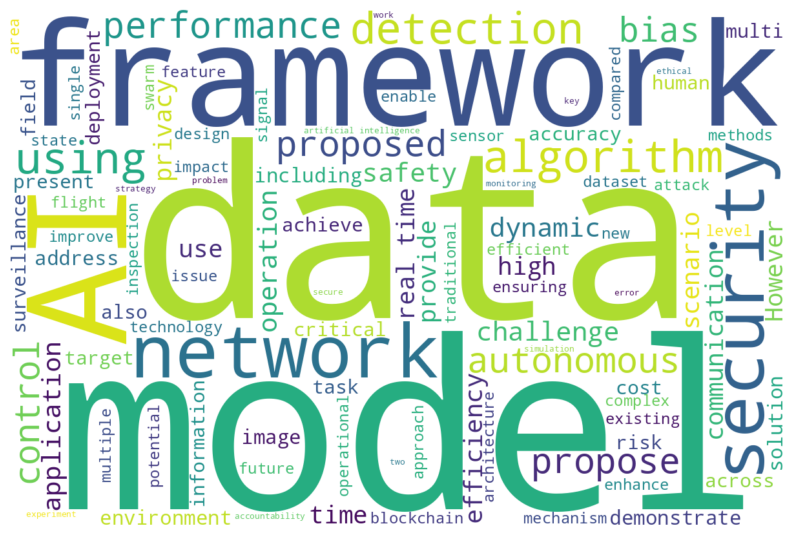

In [ ]:

nltk.download('stopwords')

texto_completo = " ".join(review for review in new_df_abs.astype(str))

stop_words = set(stopwords.words('english')) 

palavras_extras = {'paper', 'study', 'result', 'analysis', 'research', 'method', 'UAV', 'drone', 'system', 
                   'drones', 'based', 'systems', 'unmanned', 'aerial', 'vehicle', 'UAVs', 'vehicles'}
stop_words.update(palavras_extras)

nuvem = WordCloud(
    width=1200, 
    height=800, 
    background_color='white',
    stopwords=stop_words,
    max_words=100,     
    colormap='viridis' 
).generate(texto_completo)

plt.figure(figsize=(10, 7))
plt.imshow(nuvem, interpolation='bilinear')
plt.axis('off')
plt.show()

# nuvem.to_file("nuvem_abstracts.png")

[nltk_data] Downloading package stopwords to /home/bradas/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


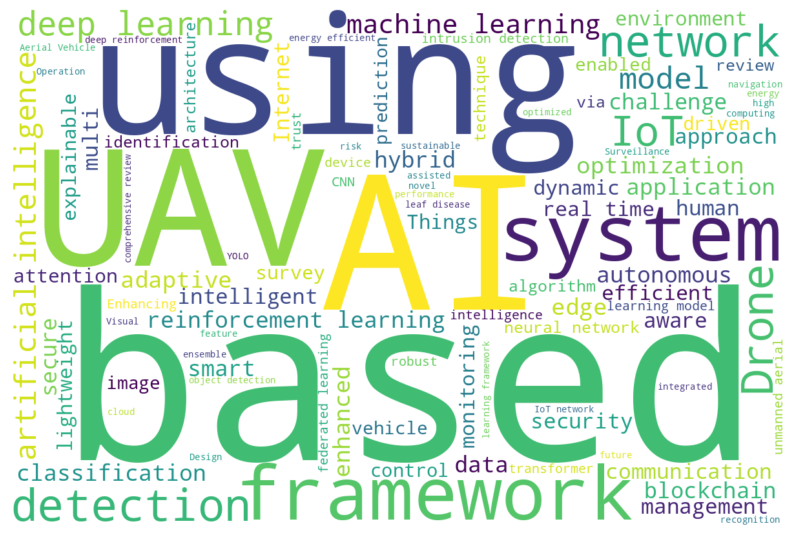

In [17]:

nltk.download('stopwords')

texto_completo = " ".join(review for review in new_df_title.astype(str))

stop_words = set(stopwords.words('english')) 

palavras_extras = {'paper', 'study', 'result', 'analysis', 'research', 'method'}
stop_words.update(palavras_extras)

nuvem = WordCloud(
    width=1200, 
    height=800, 
    background_color='white',
    stopwords=stop_words,
    max_words=100,     
    colormap='viridis' 
).generate(texto_completo)

plt.figure(figsize=(10, 7))
plt.imshow(nuvem, interpolation='bilinear')
plt.axis('off')
plt.show()

# nuvem.to_file("nuvem_abstracts.png")